<a href="https://colab.research.google.com/github/edduchzsant21-prog/Hugo/blob/main/geometr%C3%ADa_de_ocupaci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis Multidimensional de Activos (10 Activos - 10 Años)
Este cuaderno contiene la estructura completa (Pasos 1 al 11) para implementar el modelo de análisis basado en ángulos, quintiles y dinámicas de ocupación.

### Paso 1: Descargar precios de activos
Vamos a instalar y utilizar la biblioteca `yfinance` para descargar los precios de cierre ajustados de un par de activos de prueba (por ejemplo, SPY y QQQ) para simular el análisis bidimensional.

### Configuración de Activos (10 Activos y Rango de 10 Años)
Definimos los 10 tickers representativos y el rango temporal de 10 años.

In [9]:
!pip install -q yfinance

### Paso 2: Calcular retornos logarítmicos ($b_t$)
El retorno logarítmico se define como $b_t = \ln(P_t / P_{t-1})$ para cada activo.

In [10]:
!pip install -q yfinance

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Descargamos datos históricos usando auto_adjust=True para obtener Close de forma segura
tickers = ['BTC-USD', 'SPY', 'QQQ']
raw_data = yf.download(tickers, start='2023-01-01', end='2024-01-01', auto_adjust=True)

# Extraemos la sección 'Close' y limpiamos filas con valores faltantes (causados por diferencias de calendario entre BTC y acciones)
data = raw_data['Close'].dropna()
display(data.head())

[*********************100%***********************]  3 of 3 completed


Ticker,BTC-USD,QQQ,SPY
Date,,,
2023-01-03,16679.857422,258.914093,363.231995
2023-01-04,16863.238281,260.147522,366.036194
2023-01-05,16836.736328,256.075104,361.858521
2023-01-06,16951.968750,263.143250,370.156677
2023-01-09,17196.554688,264.846558,369.946899


In [11]:
# Cálculo de retornos logarítmicos adaptado dinámicamente al número de columnas
log_returns = np.log(data / data.shift(1)).dropna()

# Asignamos nombres de columnas de forma dinámica basándonos en los activos presentes
log_returns.columns = [f'ret_{col.lower()}' for col in log_returns.columns]
display(log_returns.head())

,ret_btc-usd,ret_qqq,ret_spy
Date,,,
2023-01-04,0.010934,0.004753,0.007690
2023-01-05,-0.001573,-0.015778,-0.011479
2023-01-06,0.006821,0.027228,0.022673
2023-01-09,0.014325,0.006452,-0.000567
2023-01-10,0.014418,0.008429,0.006988


### Paso 3: Calcular ángulos con `atan2`
Utilizamos la función `np.arctan2(y, x)` para mapear el vector de retornos de dos dimensiones a un ángulo en radianes $[-\pi, \pi]$.

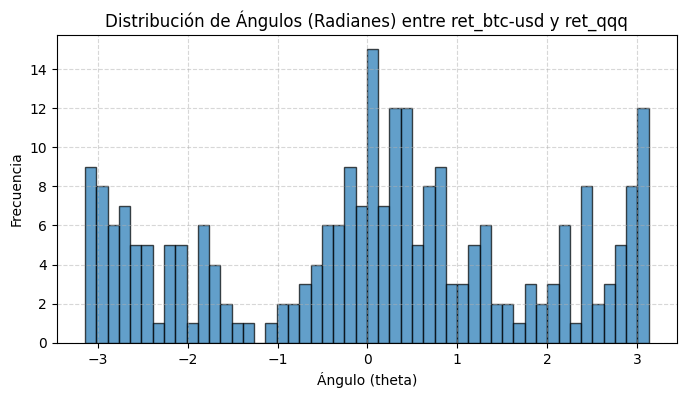

,theta
Date,
2023-01-04,0.410017
2023-01-05,-1.670152
2023-01-06,1.325339
2023-01-09,0.423190
2023-01-10,0.529026


In [12]:
# Detectar de manera dinámica las dos primeras columnas de retorno disponibles
first_asset_col = log_returns.columns[0]
second_asset_col = log_returns.columns[1]

# Calcular el ángulo theta usando arcotangente de 2 argumentos con los activos detectados
log_returns['theta'] = np.arctan2(log_returns[second_asset_col], log_returns[first_asset_col])

# Visualización de la distribución de ángulos
plt.figure(figsize=(8, 4))
plt.hist(log_returns['theta'], bins=50, edgecolor='k', alpha=0.7)
plt.title(f'Distribución de Ángulos (Radianes) entre {first_asset_col} y {second_asset_col}')
plt.xlabel('Ángulo (theta)')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

display(log_returns[['theta']].head())

## Paso 4: Definir cortes de quintiles con 200 ángulos iniciales §2

In [13]:
# Paso 4: Definir cortes de quintiles con los primeros 200 ángulos
N_INICIAL = 200

# 1. Tomamos los primeros 200 ángulos (muestra de calibración)
theta_cal = log_returns['theta'].iloc[:N_INICIAL]

# 2. Calculamos los 4 cortes: percentiles 20, 40, 60, 80
cortes = np.percentile(theta_cal, [20, 40, 60, 80])
print("Cortes (rad):", np.round(cortes, 4))

# 3. Definimos los bordes de los 5 intervalos: -inf, c20, c40, c60, c80, +inf
bordes = np.concatenate(([-np.inf], cortes, [np.inf]))
print("Bordes:", np.round(bordes, 4))

Cortes (rad): [-2.122  -0.2193  0.4961  1.8692]
Bordes: [   -inf -2.122  -0.2193  0.4961  1.8692     inf]


## Paso 5: Clasificar cada ángulo en Q1…Q5 §2

In [14]:
# TODO: Clasifica cada ángulo calculado en su respectivo quintil (Q1 a Q5)
# classified_angles = ...
pass

## Paso 6: Calcular vector de ocupación p(t) con ventana W §3

In [15]:
# TODO: Define la ventana temporal W y calcula el vector de ocupación p(t)
# W = ...
# p_t = ...
pass

## Paso 7: Calcular déficit Φ(t) §4

In [16]:
# TODO: Implementa el cálculo de déficit Φ(t)
# deficit = ...
pass

## Paso 8: Calcular velocidad V(t) §5

In [17]:
# TODO: Calcula la velocidad de cambio V(t)
# velocity = ...
pass

## Paso 9: Calcular aceleración A(t) §6

In [18]:
# TODO: Calcula la aceleración A(t)
# acceleration = ...
pass

## Paso 10: Regla de decisión f(...) → predicción §7

In [19]:
# TODO: Crea la función o regla de decisión para generar las predicciones del modelo
# def decision_rule(...):
#     return prediction
pass

## Paso 11: Evaluación fuera de muestra §8

In [20]:
# TODO: Evalúa el rendimiento del modelo en un conjunto de datos fuera de muestra
# metrics = ...
pass

In [21]:

import datetime
import numpy as np
import pandas as pd
import yfinance as yf

# ---------- Parámetros Basados en tu Modelo ----------
TICKER = "BTC-USD"
VOL_WIN = 30  # Ventana para la desviación estándar local
RANK_WIN = 250  # Días de historia para calcular el cuantil causal
N_STATES = 5  # 5 estados = Quintiles

# ---------- 1. Descarga de datos hasta el día de hoy ----------
# Al no poner fecha de fin, yfinance descarga automáticamente hasta la última vela disponible hoy.
print(f"Descargando datos históricos para {TICKER}...")
df = yf.download(TICKER, period="5y", interval="1d", auto_adjust=True, progress=False)

# Limpieza de MultiIndex si yfinance la genera
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df.dropna()

# ---------- 2. Procesamiento Causal de Retornos y Volatilidad ----------
close = df["Close"]
r = np.log(close).diff()

# Volatilidad en t-1 para evitar look-ahead bias (fuga de información)
sigma = r.rolling(VOL_WIN).std().shift(1)
x = r / sigma  # Retorno escalado por volatilidad

# ---------- 3. Cálculo Causal del Estado Actual (Quintil) ----------
def calcular_cuantil_causal(ventana):
    # Compara el último retorno contra los RANK_WIN retornos anteriores
    return (ventana[:-1] < ventana[-1]).mean()


# Aplicamos la función en ventanas móviles de tamaño RANK_WIN + 1
pct = r.rolling(RANK_WIN + 1).apply(calcular_cuantil_causal, raw=True)

# Mapeo a los estados discretos [0, 1, 2, 3, 4] que representan [Q1, Q2, Q3, Q4, Q5]
df["Estado_Geometrico"] = (
    np.floor(pct * N_STATES).clip(upper=N_STATES - 1).astype(float)
)

# ---------- 4. Mostrar el resultado de los últimos días y hoy ----------
print("\n=== ÚLTIMOS DATOS CALCULADOS (INCLUYENDO HOY) ===")
columnas_interes = ["Open", "High", "Low", "Close", "Estado_Geometrico"]
print(df[columnas_interes].tail(5))

# Guardar a un archivo CSV local si lo necesitas
# df.to_csv("datos_actualizados_hoy.csv")

Descargando datos históricos para BTC-USD...

=== ÚLTIMOS DATOS CALCULADOS (INCLUYENDO HOY) ===
Price               Open          High           Low         Close  \
Date                                                                 
2026-10-11  82912.226562  84103.625000  82722.109375  83679.468750   
2026-10-12  83679.468750  84249.218750  81681.632812  81762.562500   
2026-10-13  81762.562500  84061.093750  80962.515625  83095.125000   
2026-10-14  83095.125000  84049.062500  81345.882812  81562.492188   
2026-10-15  81573.101562  82496.742188  79789.359375  82066.500000   

Price       Estado_Geometrico  
Date                           
2026-10-11                3.0  
2026-10-12                0.0  
2026-10-13                4.0  
2026-10-14                0.0  
2026-10-15                3.0  


In [23]:

import numpy as np
import pandas as pd
import yfinance as yf

# ---------- Parámetros del Modelo ----------
TICKER = "BTC-USD"
N_STATES = 5  # Quintiles (Q1 a Q5)
VOL_WIN = 30  # Ventana de volatilidad local
RANK_WIN = 250  # Ventana para asignar el cuantil
W_OCC = 50  # Tamaño de ventana para calcular la ocupación (W)

# ---------- 1. Descarga de Datos ----------
print(f"Descargando datos históricos de {TICKER}...")
df = yf.download(TICKER, period="5y", interval="1d", auto_adjust=True, progress=False)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)
df = df.dropna()

# ---------- 2. Retornos y Estados Causales ----------
r = np.log(df["Close"]).diff()
sigma = r.rolling(VOL_WIN).std().shift(1)  # σ_{t-1} sin look-ahead

def rank_pct(a):
    return (a[:-1] < a[-1]).mean()

pct = r.rolling(RANK_WIN + 1).apply(rank_pct, raw=True)
state = np.floor(pct * N_STATES).clip(upper=N_STATES - 1)

# Crear matriz One-Hot para los 5 estados
onehot = pd.DataFrame(
    {i: (state == i).astype(float) for i in range(N_STATES)}, index=df.index
)
onehot.loc[state.isna()] = np.nan

# ---------- 3. Ocupación, Déficit, Velocidad y Aceleración ----------
# Ocupación P(t)
P = onehot.rolling(W_OCC).mean()
P.columns = [f"P_Q{i+1}" for i in range(N_STATES)]

# Déficit Phi(t) = 0.2 - P(t)
Phi = 0.2 - P
Phi.columns = [f"Phi_Q{i+1}" for i in range(N_STATES)]

# Velocidad V(t) = Phi(t) - Phi(t-1)
V = Phi.diff()
V.columns = [f"V_Q{i+1}" for i in range(N_STATES)]

# Aceleración A(t) = V(t) - V(t-1)
A = V.diff()
A.columns = [f"A_Q{i+1}" for i in range(N_STATES)]

# ---------- 4. Consolidación y Exportación ----------
# Unimos todas las métricas en un solo DataFrame
csv_final = pd.concat([P, Phi, V, A], axis=1)
csv_final.index.name = "fecha"

# Eliminamos las filas iniciales que no tienen datos suficientes debido a las ventanas
csv_final = csv_final.dropna(subset=[f"P_Q1"])

# Guardar el archivo CSV
nombre_archivo = "datos_geometria_mercado.csv"
csv_final.to_csv(nombre_archivo)

print(f"\n¡Listo! El archivo '{nombre_archivo}' ha sido generado exitosamente.")
print(f"Última fecha guardada en el CSV: {csv_final.index[-1].strftime('%Y-%m-%d')}")

Descargando datos históricos de BTC-USD...

¡Listo! El archivo 'datos_geometria_mercado.csv' ha sido generado exitosamente.
Última fecha guardada en el CSV: 2026-10-15
